In [2]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn xgboost imbalanced-learn joblib streamlit plotly

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import pickle
import plotly.express as px
from sklearn.preprocessing import MinMaxScaler

df=pd.read_csv('Customer-Churn-Records.csv')

In [3]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


In [4]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Point Earned
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203800,0.204400,3.013800,606.515100
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402842,0.403283,1.405919,225.924839
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000,0.000000,1.000000,119.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000,0.000000,2.000000,410.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000,0.000000,3.000000,605.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000,0.000000,4.000000,801.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000,1.000000,5.000000,1000.000000


In [5]:
print(df.columns.tolist())

['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'Complain', 'Satisfaction Score', 'Card Type', 'Point Earned']


In [6]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  object 
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  object 
 5   Gender              10000 non-null  object 
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non-null  int64  
 16  Card 

In [7]:
df=df.drop(columns=['CustomerId','RowNumber','Complain'])

In [8]:
df.sample(5)

,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Satisfaction Score,Card Type,Point Earned
1769,Davila,607,Germany,Male,39,2,84468.67,2,1,1,121945.42,0,5,SILVER,331
1800,Otutodilinna,713,France,Female,59,3,0.00,2,1,1,62700.08,0,5,SILVER,245
9842,Jibunoh,638,Spain,Male,30,9,136808.53,2,1,1,106642.97,0,5,GOLD,946
3389,Sheppard,420,Spain,Female,55,4,91893.32,1,1,0,144870.28,1,3,GOLD,970
206,McDonald,608,Spain,Female,41,3,89763.84,1,0,0,199304.74,1,3,PLATINUM,639


In [9]:
col = df.pop('Exited')
df['Exited'] = col

In [10]:
df.head()

,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Satisfaction Score,Card Type,Point Earned,Exited
0,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,2,DIAMOND,464,1
1,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,3,DIAMOND,456,0
2,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,3,DIAMOND,377,1
3,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,5,GOLD,350,0
4,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,5,GOLD,425,0


In [11]:
#Unique features of each column
for column in df:
    unique_val=np.unique(df[column].fillna('0'))
    nr_values=len(unique_val)
    if nr_values <= 12:
       print('The number of values for feature {} :{} -- {}'.format(column, nr_values,unique_val))
    else:
       print('The number of values for feature {} :{}'.format(column, nr_values))
       


The number of values for feature Surname :2932
The number of values for feature CreditScore :460
The number of values for feature Geography :3 -- ['France' 'Germany' 'Spain']
The number of values for feature Gender :2 -- ['Female' 'Male']
The number of values for feature Age :70
The number of values for feature Tenure :11 -- [ 0  1  2  3  4  5  6  7  8  9 10]
The number of values for feature Balance :6382
The number of values for feature NumOfProducts :4 -- [1 2 3 4]
The number of values for feature HasCrCard :2 -- [0 1]
The number of values for feature IsActiveMember :2 -- [0 1]
The number of values for feature EstimatedSalary :9999
The number of values for feature Satisfaction Score :5 -- [1 2 3 4 5]
The number of values for feature Card Type :4 -- ['DIAMOND' 'GOLD' 'PLATINUM' 'SILVER']
The number of values for feature Point Earned :785
The number of values for feature Exited :2 -- [0 1]


In [12]:
df.shape

(10000, 15)

In [14]:
df.isnull().sum()

Surname               0
CreditScore           0
Geography             0
Gender                0
Age                   0
Tenure                0
Balance               0
NumOfProducts         0
HasCrCard             0
IsActiveMember        0
EstimatedSalary       0
Satisfaction Score    0
Card Type             0
Point Earned          0
Exited                0
dtype: int64

In [13]:
#This indicates that there is no missing data here

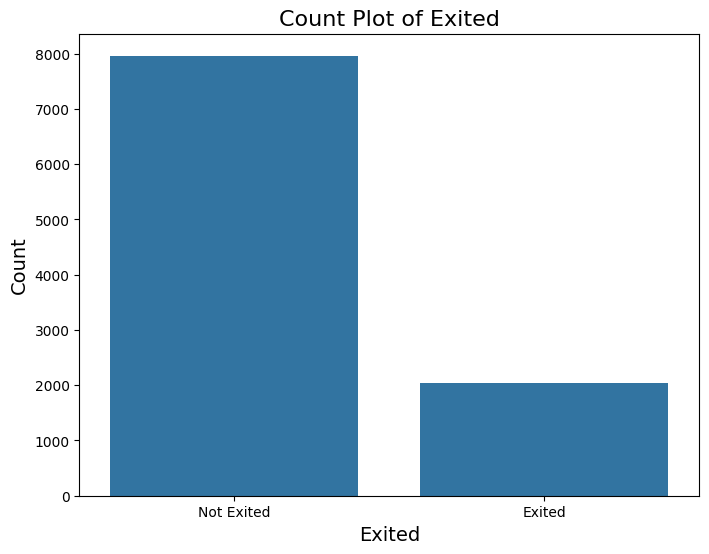

In [13]:
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x="Exited")
plt.title("Count Plot of Exited", fontsize=16)
plt.xlabel("Exited", fontsize=14)
plt.ylabel("Count", fontsize=14)
plt.xticks([0, 1], labels=["Not Exited", "Exited"])
plt.show()

In [ ]:
df_new=df[['CreditScore','Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited']]
sns.pairplot(df_new, hue='Exited',palette='Set2')

KeyboardInterrupt: 

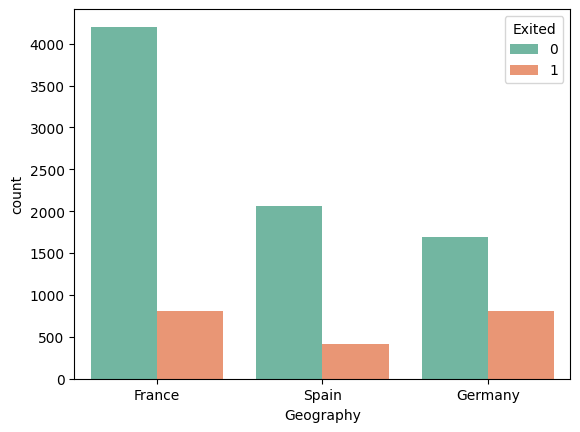

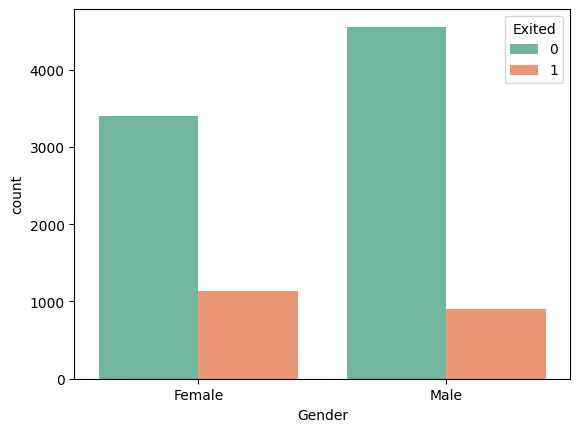

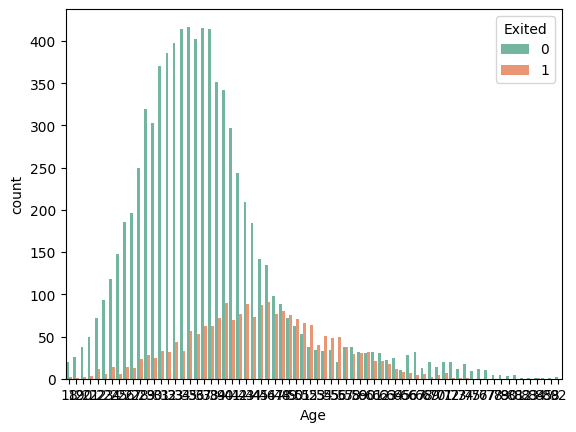

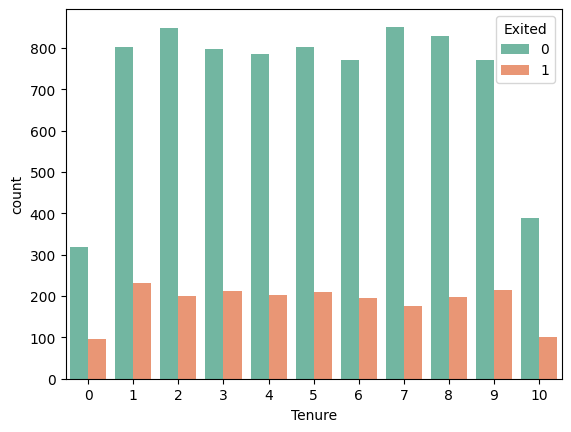

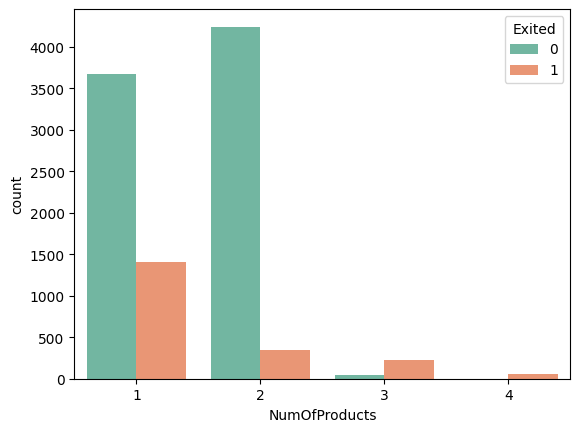

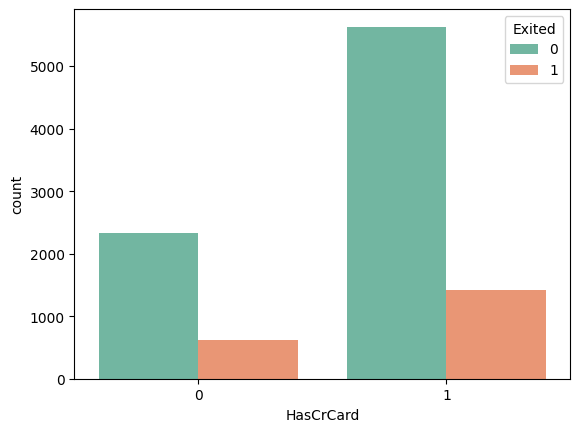

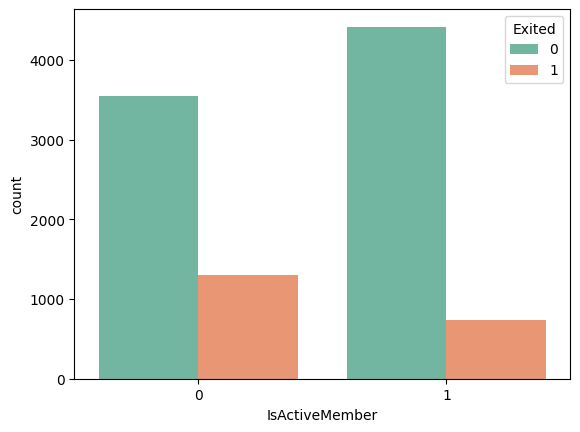

In [ ]:
features=['Geography','Gender','Age','Tenure','NumOfProducts','HasCrCard', 'IsActiveMember']
for feature in features:
    plt.figure()
    ax=sns.countplot(x=feature, data=df, hue = 'Exited', palette="Set2")
    

The median is:  652.0


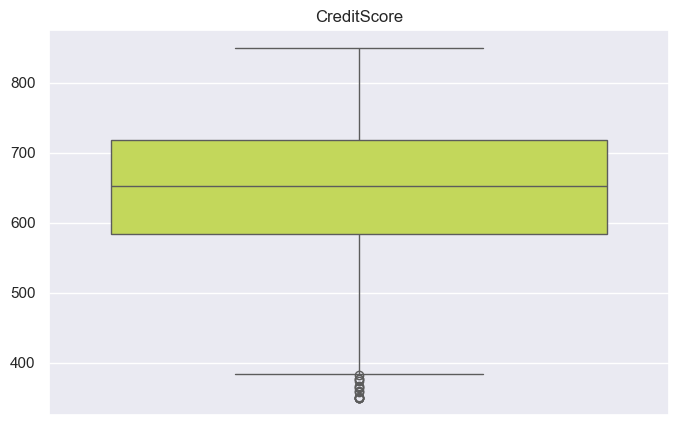

The median is:  37.0


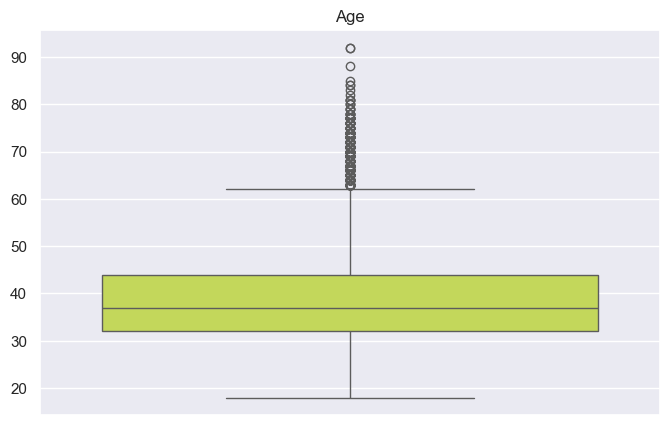

The median is:  5.0


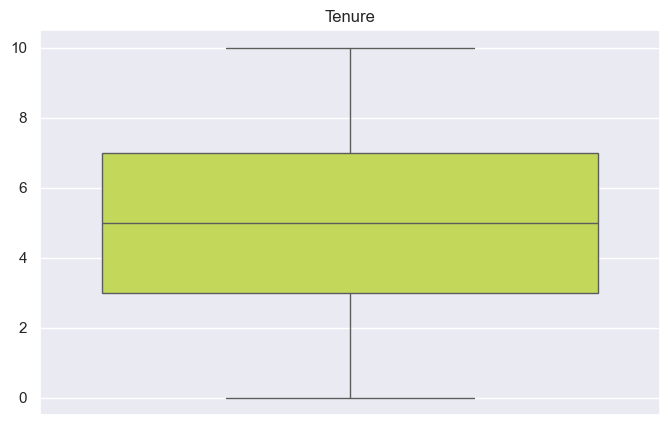

The median is:  97198.54000000001


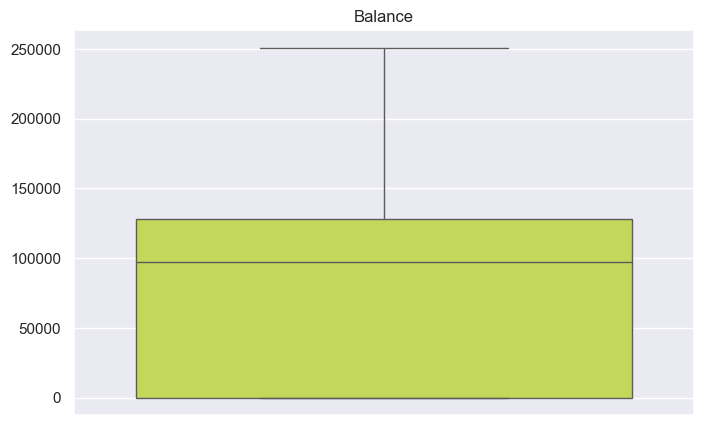

The median is:  1.0


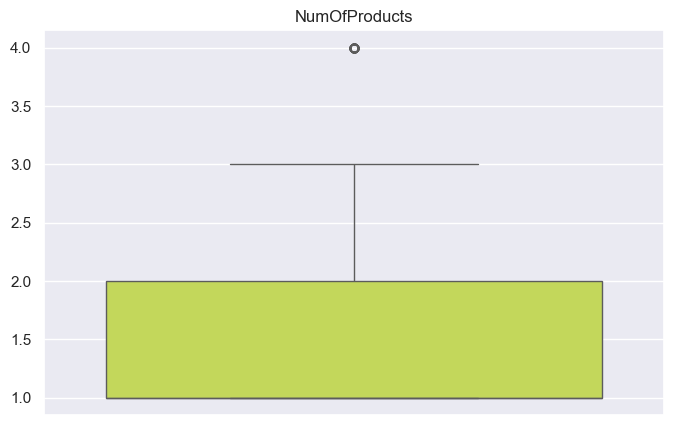

The median is:  1.0


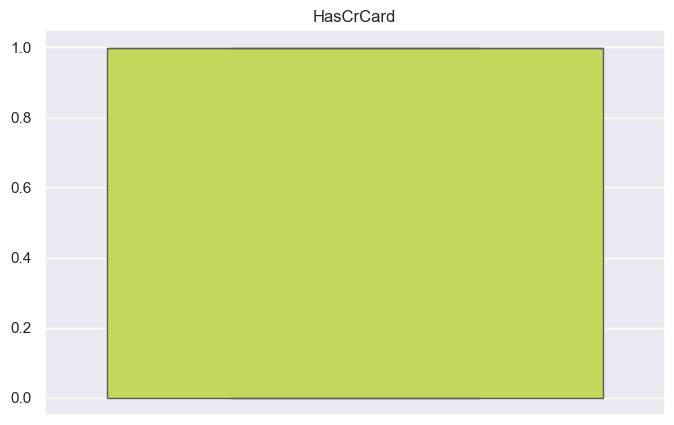

The median is:  1.0


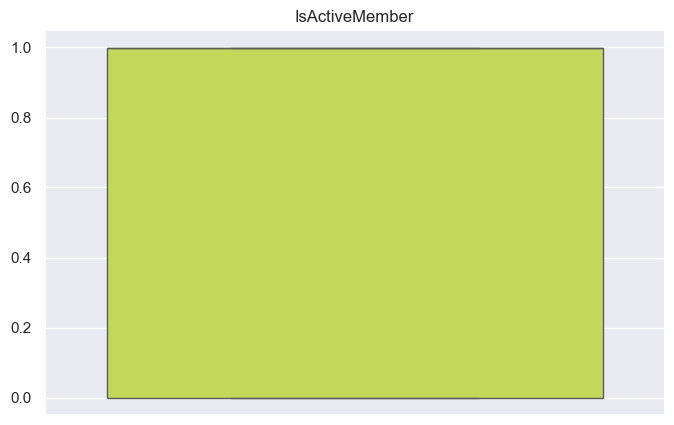

The median is:  100193.915


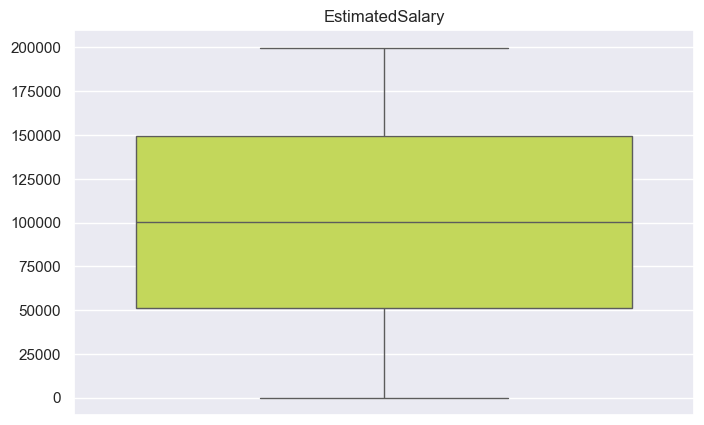

The median is:  3.0


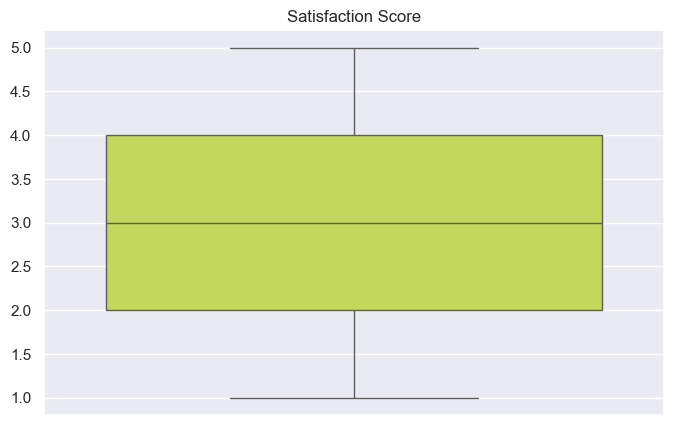

The median is:  605.0


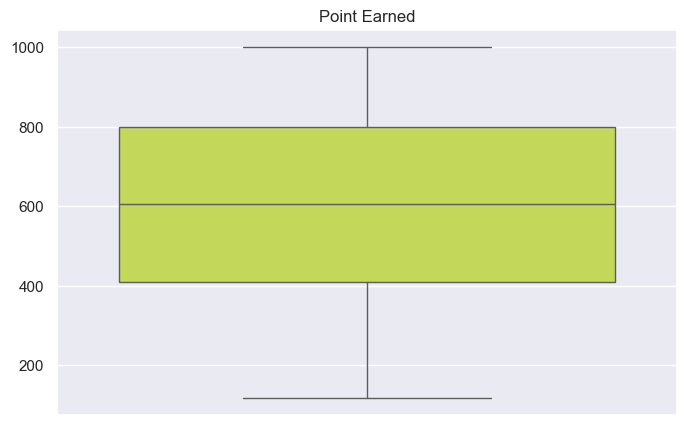

The median is:  0.0


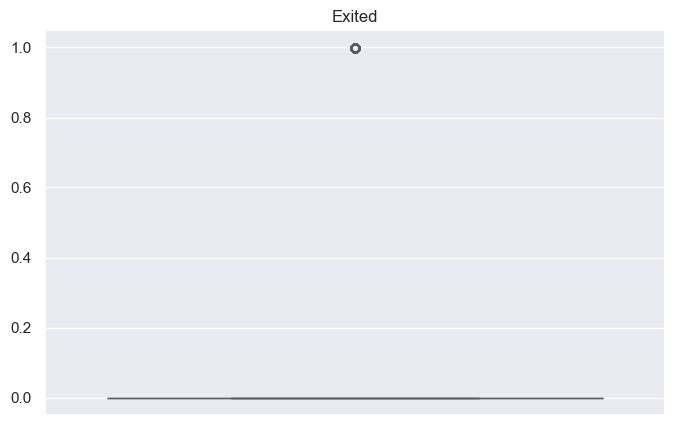

In [15]:
#Now we are going to boxplot to examine the anomalies or outliers sns set is used for setting the size of box plot here it is 8 in *5 in
numerical=['int16','int32','int64','float32','float64','float16']
variables=df.select_dtypes(include=numerical).columns
sns.set(rc={'figure.figsize':(8,5)})
for c in variables:    
    x = df[c].values
    ax = sns.boxplot(x, color = '#D1EC46')
    print('The median is: ', df[c].median())
    plt.title(c)
    plt.show()



In [16]:
df.head()

,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Satisfaction Score,Card Type,Point Earned,Exited
0,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,2,DIAMOND,464,1
1,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,3,DIAMOND,456,0
2,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,3,DIAMOND,377,1
3,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,5,GOLD,350,0
4,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,5,GOLD,425,0


In [17]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
columns_to_remove=['Surname', 'Exited']
X = df.drop(columns=columns_to_remove, errors='ignore')
y = df['Exited']
#Ye hum kar rhe before strating any scaling
X_train,X_test, y_train,y_test= train_test_split(X,y,test_size=0.25,random_state=42,stratify=y)
#Column tranformer
numeric_features = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']
categorical_features = ['Geography', 'Gender','Card Type']
preprocessor=ColumnTransformer(
            transformers=[
                        ('num',MinMaxScaler(),numeric_features),
                        ('col', OneHotEncoder(drop='first',sparse_output=False, handle_unknown='ignore'), categorical_features)
            ],
           remainder='passthrough',
    verbose_feature_names_out=False
 )
X_train_processed=preprocessor.fit_transform(X_train)
X_test_processed=preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

X_train_final = pd.DataFrame(X_train_processed, columns=feature_names, index=X_train.index)
X_test_final = pd.DataFrame(X_test_processed, columns=feature_names, index=X_test.index)

print(f"X_train shape: {X_train_final.shape}")
print(f"X_test shape: {X_test_final.shape}")
X_train_final.head()

X_train shape: (7500, 16)
X_test shape: (2500, 16)


,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male,Card Type_GOLD,Card Type_PLATINUM,Card Type_SILVER,HasCrCard,IsActiveMember,Satisfaction Score,Point Earned
2251,0.654,0.094595,0.8,0.588778,0.000000,0.212013,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,5.0,236.0
1466,0.566,0.148649,0.7,0.764791,0.000000,0.021304,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,3.0,613.0
7579,0.502,0.297297,1.0,0.575198,0.000000,0.866253,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,376.0
3647,0.758,0.662162,0.2,0.423830,0.000000,0.511946,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,2.0,948.0
4202,0.352,0.162162,0.9,0.000000,0.333333,0.504969,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,518.0


In [18]:
#Baseline model training
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
baseline_model=LogisticRegression(class_weight={0: 1.0, 1: 2.2},max_iter=1000,random_state=42)
baseline_model.fit(X_train_final,y_train)
#now for the predictions
y_pred=baseline_model.predict(X_test_final)
y_proba = baseline_model.predict_proba(X_test_final)[:, 1]
print("Confusion matrix")
print(confusion_matrix(y_test,y_pred))
print("\n Classification Report")
print(classification_report(y_test,y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba):.4f}")

Confusion matrix
[[1750  241]
 [ 258  251]]

 Classification Report
              precision    recall  f1-score   support

           0       0.87      0.88      0.88      1991
           1       0.51      0.49      0.50       509

    accuracy                           0.80      2500
   macro avg       0.69      0.69      0.69      2500
weighted avg       0.80      0.80      0.80      2500

ROC-AUC Score: 0.7839


Our Baseline model is giving us almost 80% accuracy and the now we will use XGboost yo improve the accuracy

In [21]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
neg,pos=y_train.value_counts()[0],y_train.value_counts()[1]
ratio=neg/pos
print(ratio)
xgb_model=Pipeline(steps=[
     ("preprocessor",preprocessor),
     ("classifier",XGBClassifier(
         n_estimators=300, max_depth=4, learning_rate=0.05,
         subsample=0.9,colsample_bytree=0.9, objective="binary:logistic",scale_pos_weight=1,
         eval_metric="logloss", random_state=42,
     ))
])
xgb_model.fit(X_train, y_train)
xgb_predictions = xgb_model.predict(X_test)
xgb_probabilities = xgb_model.predict_proba(X_test)[:, 1]
print(" Confusion Matrix ")
print(confusion_matrix(y_test, xgb_predictions))
print("\nClassification Report ")
print(classification_report(y_test, xgb_predictions, target_names=["Stayed", "Churned"], zero_division=0))
print(f"XGBoost ROC-AUC: {roc_auc_score(y_test, xgb_probabilities):.4f}")

3.9051667756703727
 Confusion Matrix 
[[1910   81]
 [ 257  252]]

Classification Report 
              precision    recall  f1-score   support

      Stayed       0.88      0.96      0.92      1991
     Churned       0.76      0.50      0.60       509

    accuracy                           0.86      2500
   macro avg       0.82      0.73      0.76      2500
weighted avg       0.86      0.86      0.85      2500

XGBoost ROC-AUC: 0.8752


The difference between Baseline Model and XGBoost

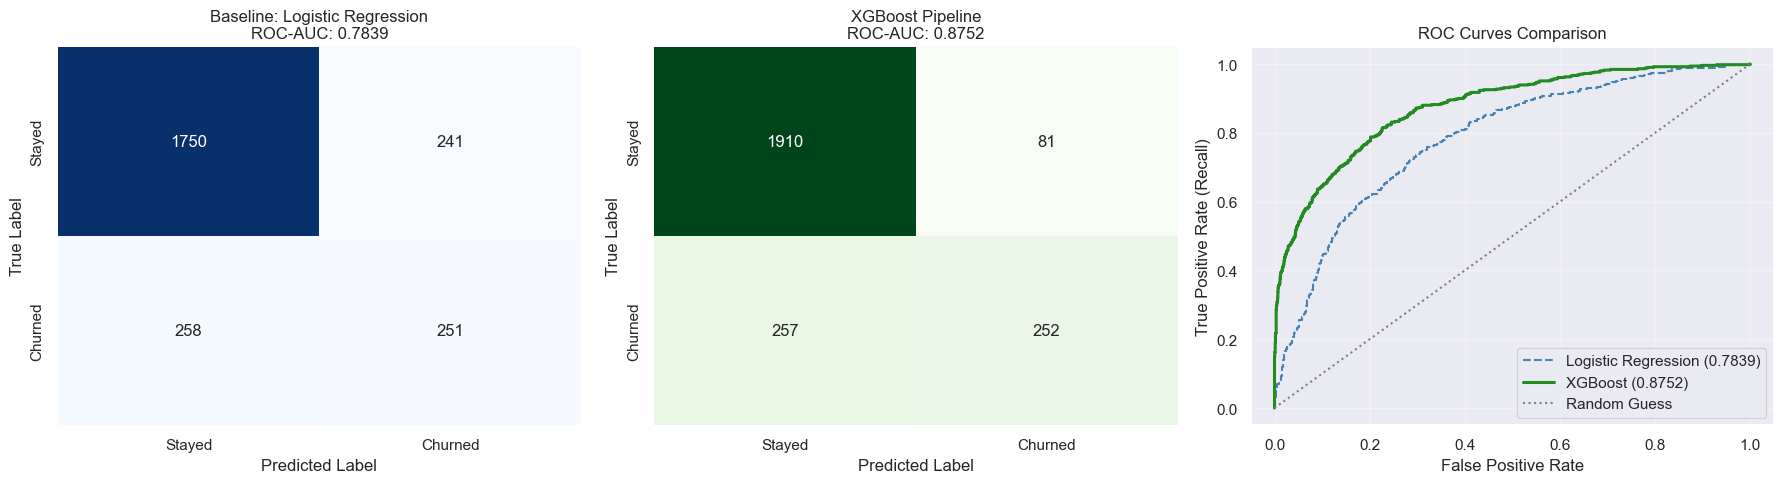

Model saved successfully as: customer_churn_xgb_pipeline.pkl

Sample verification output:
Predicted classes: [0 1 0]
Churn probabilities: [0.1335 0.5544 0.0326]


In [23]:
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cm_lr = confusion_matrix(y_test, y_pred)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title(f"Baseline: Logistic Regression\nROC-AUC: {roc_auc_score(y_test, y_proba):.4f}")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")
axes[0].set_xticklabels(['Stayed', 'Churned'])
axes[0].set_yticklabels(['Stayed', 'Churned'])


cm_xgb = confusion_matrix(y_test, xgb_predictions)
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False)
axes[1].set_title(f"XGBoost Pipeline\nROC-AUC: {roc_auc_score(y_test, xgb_probabilities):.4f}")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")
axes[1].set_xticklabels(['Stayed', 'Churned'])
axes[1].set_yticklabels(['Stayed', 'Churned'])


fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_probabilities)

axes[2].plot(fpr_lr, tpr_lr, label=f"Logistic Regression ({roc_auc_score(y_test, y_proba):.4f})", color='steelblue', linestyle='--')
axes[2].plot(fpr_xgb, tpr_xgb, label=f"XGBoost ({roc_auc_score(y_test, xgb_probabilities):.4f})", color='forestgreen', linewidth=2.2)
axes[2].plot([0, 1], [0, 1], color='gray', linestyle=':', label='Random Guess')
axes[2].set_title("ROC Curves Comparison")
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate (Recall)")
axes[2].legend(loc="lower right")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

pkl_filename = "customer_churn_xgb_pipeline.pkl"
joblib.dump(xgb_model, pkl_filename)
print(f"Model saved successfully as: {pkl_filename}")

loaded_pipeline = joblib.load(pkl_filename)
test_sample = X_test.iloc[:3]
print("\nSample verification output:")
print("Predicted classes:", loaded_pipeline.predict(test_sample))
print("Churn probabilities:", loaded_pipeline.predict_proba(test_sample)[:, 1].round(4))